## Sentiment_Analysis_of_Customer_Reviews

#### Import the dataset

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv('C:\Tasks\Sentiment_Analysis_of_Customer_Reviews\Data\IMDB Dataset.csv')
print(df.shape)


<>:1: SyntaxWarning: invalid escape sequence '\T'
<>:1: SyntaxWarning: invalid escape sequence '\T'
C:\Users\aswat\AppData\Local\Temp\ipykernel_14196\3894760075.py:1: SyntaxWarning: invalid escape sequence '\T'
  df = pd.read_csv('C:\Tasks\Sentiment_Analysis_of_Customer_Reviews\Data\IMDB Dataset.csv')


(50000, 2)


In [3]:
df.head()


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


##### Missing Values and Duplicates

In [5]:
df.isnull().sum()

review       0
sentiment    0
dtype: int64

In [6]:
print("Duplicates:",df.duplicated().sum())

Duplicates: 418


In [7]:
df = df.drop_duplicates().reset_index(drop=True)
print("Duplicates:",df.duplicated().sum())
df.shape

Duplicates: 0


(49582, 2)

##### Distribution check:

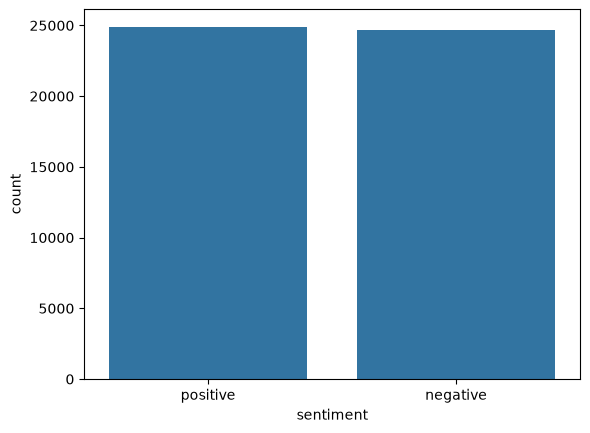

In [8]:
sns.countplot(x='sentiment',data=df)
plt.show()

##### review length

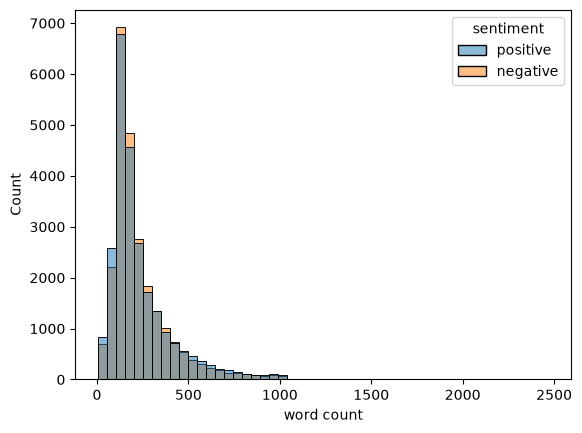

In [9]:
df['word count']=df['review'].str.split().str.len()
sns.histplot(data=df,x='word count',hue='sentiment',bins=50)
plt.show()

#### Find the common words in reviews

In [10]:
from collections import Counter
import re 
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS as SW
def top_words(text,n=15):
    words = re.findall(r"[a-z]+"," ".join(text).lower())
    return Counter(w for w in words if w not in SW and len(w)>2).most_common(n)

for labels in ["positive","negative"]:
    print(top_words(df[df['sentiment']==labels]['review']))



[('film', 41971), ('movie', 37660), ('like', 17651), ('good', 14966), ('just', 14057), ('story', 12899), ('great', 12889), ('time', 12701), ('really', 10707), ('people', 8685), ('love', 8658), ('best', 8480), ('life', 8105), ('way', 7833), ('films', 7581)]
[('movie', 49618), ('film', 37180), ('like', 22192), ('just', 20870), ('good', 14581), ('bad', 14563), ('really', 12217), ('time', 12205), ('don', 10502), ('story', 10074), ('people', 9337), ('make', 9266), ('movies', 8246), ('plot', 8128), ('acting', 8004)]


##### Clean the data

In [11]:
import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
nltk.download("stopwords",quiet=True)
nltk.download("wordnet",quiet=True)

lemma = WordNetLemmatizer()
stop = set(stopwords.words('english')) - {'not', 'no', 'nor', 'never'}

def clean_text(text):
    text = text.lower()
    text =  re.sub(r"[^a-z\s]"," ",text) 
    text = re.sub("<.*?>"," ",text)
    return " ".join(lemma.lemmatize(w)  for w in text.split() if w not in stop)

df['cleaned_review'] = df['review'].apply(clean_text)
df["label"] = (df["sentiment"] == "positive").astype(int)
print(df['cleaned_review'][1])

wonderful little production br br filming technique unassuming old time bbc fashion give comforting sometimes discomforting sense realism entire piece br br actor extremely well chosen michael sheen not got polari voice pat truly see seamless editing guided reference williams diary entry not well worth watching terrificly written performed piece masterful production one great master comedy life br br realism really come home little thing fantasy guard rather use traditional dream technique remains solid disappears play knowledge sens particularly scene concerning orton halliwell set particularly flat halliwell mural decorating every surface terribly well done


##### Save the cleaned dataset

In [12]:
out = df[["cleaned_review", "label"]]          
out.to_csv("../Data/cleaned.csv", index=False)

##### Load the cleaned dataset

In [13]:

df = pd.read_csv("C:/Tasks/Sentiment_Analysis_of_Customer_Reviews/Data/cleaned.csv")


##### Split the train and test data

In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(df['cleaned_review'],df['label'],test_size=0.2,random_state=42,stratify=df['label'])
print(x_train.shape,y_train.shape)
print(y_train.value_counts(normalize=True))

(39665,) (39665,)
label
1    0.501878
0    0.498122
Name: proportion, dtype: float64


##### Feature engineering

In [15]:
from sklearn.feature_extraction.text import CountVectorizer
# BOW
bow = CountVectorizer(max_features=10000,ngram_range=(1,2))
x_train_bow = bow.fit_transform(x_train)
x_test_bow = bow.transform(x_test)
print("BoW:", x_train_bow.shape)

BoW: (39665, 10000)


In [16]:
# word embeddings
from gensim.models import Word2Vec
train_tokens = [t.split() for t in x_train]
test_tokens = [t.split() for t in x_test]
w2v = Word2Vec(sentences=train_tokens, vector_size=100, window=5,
               min_count=2, workers=4, epochs=10, seed=42)
def review_vector(tokens):
    vecs = [w2v.wv[w] for w in tokens if w in w2v.wv]
    return np.mean(vecs, axis=0) if vecs else np.zeros(w2v.vector_size)

x_train_w2v = np.array([review_vector(t) for t in train_tokens])
x_test_w2v = np.array([review_vector(t) for t in test_tokens])
print("Word2Vec:", x_train_w2v.shape)


Word2Vec: (39665, 100)


#### Model Training:

In [17]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
nb = MultinomialNB()
nb.fit(x_train_bow, y_train)
pred = nb.predict(x_test_bow)

nb_bow = [accuracy_score(y_test, pred), precision_score(y_test, pred),
          recall_score(y_test, pred), f1_score(y_test, pred)]
print("Naive Bayes + BoW:", [round(x, 4) for x in nb_bow])

Naive Bayes + BoW: [0.8606, 0.8589, 0.8644, 0.8616]


In [18]:
from sklearn.linear_model import LogisticRegression
#bow
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_bow, y_train)
pred = lr.predict(x_test_bow)
lr_bow = [accuracy_score(y_test, pred), precision_score(y_test, pred),
          recall_score(y_test, pred), f1_score(y_test, pred)]

# Word2Vec
lr = LogisticRegression(max_iter=1000)
lr.fit(x_train_w2v, y_train)
pred = lr.predict(x_test_w2v)
lr_w2v = [accuracy_score(y_test, pred), precision_score(y_test, pred),
          recall_score(y_test, pred), f1_score(y_test, pred)]

In [20]:
from sklearn.svm import LinearSVC
# BoW
svm = LinearSVC()
svm.fit(x_train_bow, y_train)
pred = svm.predict(x_test_bow)
svm_bow = [accuracy_score(y_test, pred), precision_score(y_test, pred),
           recall_score(y_test, pred), f1_score(y_test, pred)]

# Word2Vec
svm = LinearSVC()
svm.fit(x_train_w2v, y_train)
pred = svm.predict(x_test_w2v)
svm_w2v = [accuracy_score(y_test, pred), precision_score(y_test, pred),
           recall_score(y_test, pred), f1_score(y_test, pred)]

In [21]:
from sklearn.ensemble import RandomForestClassifier
# BoW
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(x_train_bow, y_train)
pred = rf.predict(x_test_bow)
rf_bow = [accuracy_score(y_test, pred), precision_score(y_test, pred),
          recall_score(y_test, pred), f1_score(y_test, pred)]

# Word2Vec
rf = RandomForestClassifier(n_estimators=100, n_jobs=-1, random_state=42)
rf.fit(x_train_w2v, y_train)
pred = rf.predict(x_test_w2v)
rf_w2v = [accuracy_score(y_test, pred), precision_score(y_test, pred),
          recall_score(y_test, pred), f1_score(y_test, pred)]

In [22]:
comparison = pd.DataFrame(
    [
        ["Naive Bayes",         "BoW"]      + nb_bow,
        ["Logistic Regression", "BoW"]      + lr_bow,
        ["Logistic Regression", "Word2Vec"] + lr_w2v,
        ["SVM",                 "BoW"]      + svm_bow,
        ["SVM",                 "Word2Vec"] + svm_w2v,
        ["Random Forest",       "BoW"]      + rf_bow,
        ["Random Forest",       "Word2Vec"] + rf_w2v,
    ],
    columns=["Model", "Features", "Accuracy", "Precision", "Recall", "F1"],
).sort_values("F1", ascending=False).reset_index(drop=True)

comparison.round(4)

,Model,Features,Accuracy,Precision,Recall,F1
0,Logistic Regression,BoW,0.8755,0.8746,0.8776,0.8761
1,SVM,Word2Vec,0.8683,0.8625,0.8774,0.8699
2,Logistic Regression,Word2Vec,0.8661,0.8604,0.8752,0.8677
3,Naive Bayes,BoW,0.8606,0.8589,0.8644,0.8616
4,Random Forest,BoW,0.8534,0.8496,0.8602,0.8548
5,SVM,BoW,0.8534,0.8561,0.8509,0.8535
6,Random Forest,Word2Vec,0.8400,0.8296,0.8571,0.8432


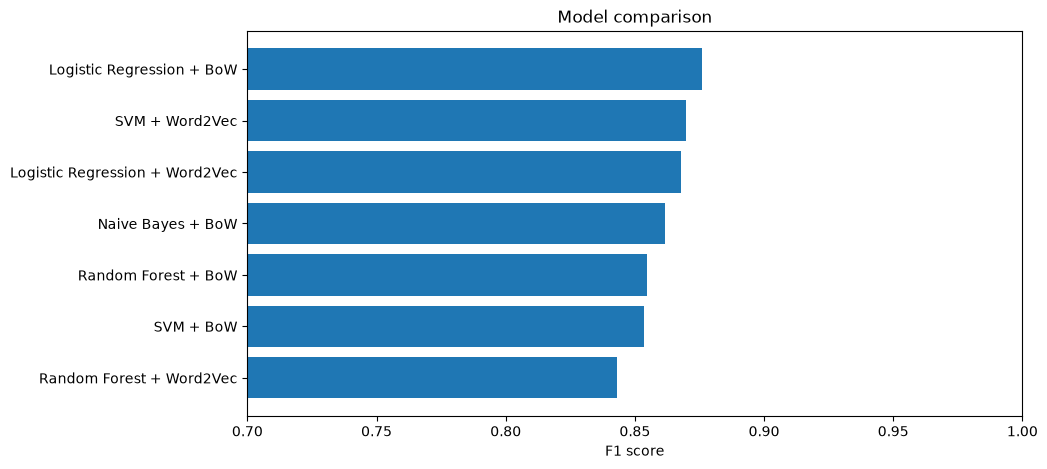

In [23]:
labels = comparison["Model"] + " + " + comparison["Features"]
plt.figure(figsize=(10, 5))
plt.barh(labels[::-1], comparison["F1"][::-1])
plt.xlabel("F1 score")
plt.title("Model comparison")
plt.xlim(0.7, 1.0)
plt.show()